KBTU | DSSC5113 Algorithms of Computer Vision | Bonus Project

# Kazakh Profanity Detection

**Master's Bonus Project | Individual work | 3 points | Second attestation**

**Submission deadline: 21 November 2026.**
The defense schedule will be announced separately on Teams.

Aidyn Abirov | Fall 2026

## Your task

Create a GitHub repository with a trained model that reads a Kazakh product review or comment about goods and predicts whether it contains Kazakh profanity. Prepare the data, train the model, evaluate it, and explain your complete solution during an individual defense.

The input is one comment or sentence. The output is a binary label: **0 = no Kazakh profanity; 1 = Kazakh profanity present**. If your model provides a probability or decision score, display it alongside the prediction. **You must train or fine-tune the model yourself and include the training code and saved results.**

## 1. Prepare the dataset

Use publicly available Kazakh reviews/comments, a suitable Kazakh text dataset, or prepare and label your own collection. Explain how the data relates to Kazakh product reviews. Provide the source, access instructions, labeling method, total sample count, and class distribution. Clearly identify any synthetic examples.

Define your labeling rules for Kazakh profanity, including how you handle mixed-language comments. A negative review is not automatically profane. Explain how you treat masked words, spelling variations, and ambiguous cases. If an existing dataset labels toxicity or sentiment, check that its labels match this task and revise them where needed. Include a few labeled examples in the README.

Create separate training, validation, and test sets. Remove duplicates and keep near-duplicates in the same split. Document the split sizes and random seed. Fit any vocabulary or learned text preprocessing on training data only. Do not include reviewer names, contact details, or other personal information in the repository.

### My solution: data

Source. I use KazSAnDRA from ISSAI (https://github.com/IS2AI/KazSAnDRA, CC BY 4.0). It has about 168k real Kazakh reviews from an app store, a book store, maps and online marketplaces. These are reviews of products: apps, books, places and goods. They look like product comments: short, informal, often mixed with Russian, with many spelling mistakes. The script downloads the CSV files from GitHub, so no login is needed. To start my word list I also used the Kazakh Swear Words dataset (https://huggingface.co/datasets/Rustem-Kaimolla/kazakh-swear-words, MIT).

KazSAnDRA only has sentiment labels (positive or negative), so they do not fit this task. I made new labels myself:

1. Regex rules for obscene words, with spelling variants (src/lexicon.py). A match gives label 1.
2. Unclear matches were checked by hand: 1,050 texts (data/manual_labels.csv). These are risky single matches like "ам", "көт", "сығу", "боқ", "зб", masked words like "бл**", and words that only look like profanity, such as "педикюр", "епті", "сигнал" or the surname "Далбаев".
3. Everything else gets label 0. I checked 120 random negatives and added the few forms I had missed.

There are no synthetic examples. All texts are real reviews.

Labeling rules:

- Label 1 means obscene or vulgar words: sexual words and body parts (қотақ, ам, көт, сігу and their forms), mother insults (шешеңді ..., шшс, 667), words like жәлеп or қаншық, and excrement words (боқ, говно).
- Mixed language: Russian swear words inside a Kazakh comment (бля, нахуй, пиздец, заебал/зайбал, сука, далбаёб) are label 1. People mix the two languages a lot, and a moderator would remove them too.
- Mild insults are label 0: мал, ешак, ақымақ, жынды, тупой, қоқыс. A negative review is not profane. "Мал ойын, ашылмайды" is 0.
- Talking about swearing without swearing is 0, for example "боқ сөз айтпаңдар".
- Masked or changed spelling counts as profanity when the word is clear: "қ***бас", "бл**", "к0тақ", "зб" (short for заебал). The rules join letters split by "*" or ".", map Latin look-alike letters to Cyrillic, and shorten repeated letters.
- Ambiguous cases ("ой шешең...", "нау", "ш**********" where the word is unclear) are 0, because I only mark 1 when I am sure.

Splits. I remove exact duplicates first. Then I group near-duplicates (letters only, repeated letters collapsed, so "Керемееет!!" and "керемет" become one group). Each group goes to only one split. The split is 80/10/10, stratified by label, with seed 42. I keep all profane reviews and sample 20,000 clean ones. Half of the clean ones come from negative reviews and half from positive, and I also add all clean reviews with mild insults. This way the model must learn that "negative" is not the same as "profane".

Privacy. KazSAnDRA has no reviewer names. I still mask links, e-mails, @usernames, phone numbers and surnames (-ов, -ова, -ұлы ...) in the text.

In [1]:
import sys, os
sys.path.insert(0, "src")
import pandas as pd
import prepare_data

data = prepare_data.main(seed=42, n_neg=20000)

raw reviews: 167961, after exact dedup: 166049, final dataset: 22530
near-duplicate groups: 22351
       count  profane
split                
test    2246      251
train  18038     2033
val     2246      250


In [2]:
print("profane share:", round(data.label.mean(), 3))
print(pd.crosstab(data.domain, data.label, margins=True))
print(pd.crosstab(data.sentiment.map({0: "negative review", 1: "positive review"}), data.label))
print(data.label_source.value_counts())

profane share: 0.112
label          0     1    All
domain                       
appstore   16173  2517  18690
bookstore    537    10    547
mapping      940     7    947
market      2346     0   2346
All        19996  2534  22530
label                0     1
sentiment                   
negative review  10018  1372
positive review   9978  1162
label_source
rule      21481
manual     1049
Name: count, dtype: int64


In [3]:
pd.set_option("display.max_colwidth", 90)
ex = pd.concat([data[data.label == 1].sample(6, random_state=1), data[data.label == 0].sample(6, random_state=1)])
ex[["text", "label", "sentiment", "domain"]]

,text,label,sentiment,domain
148884,Пиздец ойын екен ебааааайт,1,1,appstore
78307,Е ма метеорит бірінші рет көріп тұрм шешеңсгейн қотақбас,1,1,appstore
141953,Ойнамандар өтірік ойын ұтқан ақшаны шығара алмайсың 33700 ұттым ешқандай кашалокке ауд...,1,0,appstore
128070,Тез қосылмаит бләтттар,1,1,appstore
78039,Сыкты ойн,1,1,appstore
124599,Шшс чит тартпаңдар акк қа бан беред 100%,1,0,appstore
13093,"А в Кыргызстане доступно, Lamoda",0,1,appstore
41890,Өте керемет екен қазақша таба алмай жүр едім жазып алғаным жақсы болды,0,1,appstore
97232,Просто дериски жазып алсаң өкінбеисің пубкка қарағанда жақсы оиын екен 5левл ға жетіп ...,0,0,appstore
44015,Пазорго мынау озмиздин елде турып дурыс жасамайтын нарсени истеп. Каншама акша болинип...,0,1,appstore


Most profane comments come from the app store domain (games and apps). Marketplace reviews of goods are almost always polite, so the model mostly sees profanity in app reviews. I come back to this in the limitations.

## 2. Train one classification model

Choose a suitable trainable text classifier. Train a small model or fine-tune a pretrained one. Explain why you chose it, how text becomes model input, and how you handle long comments, punctuation, and unknown words or tokens.

Record the model, dependencies, training settings, random seed, and preprocessing steps. Use validation data to select settings and any decision threshold. Save the trained model and all preprocessing/tokenizer files needed for inference. **One trained model is sufficient; multiple architectures and repeated-seed studies are not required.**

### My solution: model

Model: a character-level CNN trained from scratch (src/model.py).

Why: Kazakh profanity is written in many ways: қотақ, котак, қотағым, к0тақ, қ*тақ, Latin letters, Russian mat written in Kazakh style (зайбал, далбайоп). A word-level model would see most of these as unknown words. Characters always exist in the vocabulary, and a CNN filter of width 2-5 learns short pieces like "қот", "сіг", "бля" anywhere in the text. The model is small (about 145k parameters), trains on a laptop CPU in about 7 minutes, and the saved file is under 1 MB, so it fits in GitHub.

How text becomes input:

1. Lowercase, and letters repeated 3 or more times are cut to 2 ("нахуууй" becomes "нахууй").
2. Each character becomes an id from a vocabulary built on training data only. Characters seen fewer than 3 times in train become <unk>, which covers rare emoji and unknown symbols.
3. Max length is 300 characters. Longer comments (about 1%) keep the first 150 and the last 150 characters, because swear words are often at the start or the end. Shorter ones are padded.
4. Embedding (64) → 4 Conv1d layers with kernel 2, 3, 4, 5 (128 filters each) → ReLU → global max-pool → dropout 0.3 → linear → 1 logit.

Punctuation and emoji stay in the input; they are just characters. Max-pooling means the position of the bad word does not matter.

Training: BCE loss with logits, Adam (lr 1e-3, weight decay 1e-5), batch 128, 15 epochs, seed 42. Batches group comments of similar length, so there is less padding. After each epoch I compute validation F1 and keep the best epoch. The decision threshold is also chosen on validation, by the best F1 over 0.05-0.95. The test set is not used here.

Saved files (models/): char_cnn.pt (weights), vocab.json (character vocabulary), config.json (all settings, seed, chosen threshold). Dependencies are in requirements.txt.

In [4]:
import train
cfg, history = train.main(dict(train.DEFAULTS))
history

vocab size 454, train 18038, val 2246
epoch  1 loss 0.2129 val F1@0.5 0.7304 best val F1 0.7951 (thr 0.23) 33s
epoch  2 loss 0.1247 val F1@0.5 0.8238 best val F1 0.8688 (thr 0.34) 30s
epoch  3 loss 0.0889 val F1@0.5 0.8833 best val F1 0.8875 (thr 0.44) 34s
epoch  4 loss 0.0687 val F1@0.5 0.8874 best val F1 0.9110 (thr 0.36) 35s
epoch  5 loss 0.0544 val F1@0.5 0.9046 best val F1 0.9140 (thr 0.59) 28s
epoch  6 loss 0.0417 val F1@0.5 0.9268 best val F1 0.9303 (thr 0.54) 31s
epoch  7 loss 0.0410 val F1@0.5 0.9110 best val F1 0.9331 (thr 0.21) 37s
epoch  8 loss 0.0335 val F1@0.5 0.9271 best val F1 0.9347 (thr 0.56) 39s
epoch  9 loss 0.0305 val F1@0.5 0.9278 best val F1 0.9365 (thr 0.29) 30s
epoch 10 loss 0.0241 val F1@0.5 0.9347 best val F1 0.9520 (thr 0.29) 28s
epoch 11 loss 0.0224 val F1@0.5 0.9366 best val F1 0.9503 (thr 0.27) 32s
epoch 12 loss 0.0207 val F1@0.5 0.9247 best val F1 0.9384 (thr 0.12) 29s
epoch 13 loss 0.0166 val F1@0.5 0.9380 best val F1 0.9501 (thr 0.14) 29s
epoch 14 loss

,epoch,train_loss,val_f1_at_0_5,val_best_f1,val_best_thr
0,1,0.212900,0.730392,0.795132,0.23
1,2,0.124671,0.823799,0.868817,0.34
2,3,0.088922,0.883333,0.887526,0.44
3,4,0.068725,0.887446,0.911017,0.36
4,5,0.054378,0.904564,0.914046,0.59
5,6,0.041690,0.926829,0.930328,0.54
6,7,0.041034,0.911017,0.933063,0.21
7,8,0.033512,0.927126,0.934694,0.56
8,9,0.030508,0.927835,0.936508,0.29
9,10,0.024066,0.934694,0.952000,0.29


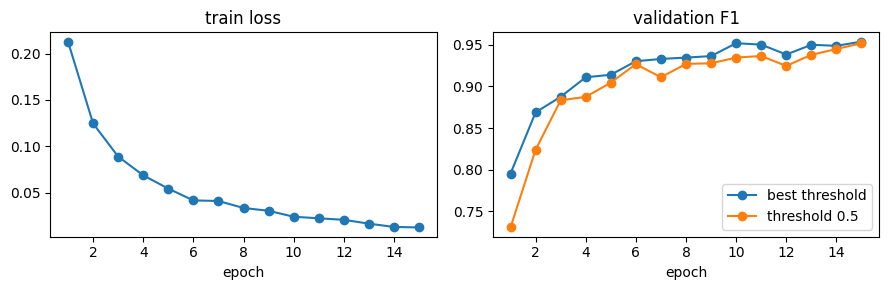

chosen epoch: 15  threshold: 0.51  val F1: 0.9539


In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(history.epoch, history.train_loss, marker="o"); ax[0].set_title("train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(history.epoch, history.val_best_f1, marker="o", label="best threshold")
ax[1].plot(history.epoch, history.val_f1_at_0_5, marker="o", label="threshold 0.5")
ax[1].set_title("validation F1"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()
print("chosen epoch:", cfg["best_epoch"], " threshold:", cfg["threshold"], " val F1:", round(cfg["val_f1"], 4))

## 3. Evaluate the result

Evaluate once on the held-out test set after selecting your settings. Report precision, recall, and F1 for the profanity class, plus a confusion matrix and the number of test examples. Explain what a false positive and a false negative mean in this task, and discuss which errors matter for moderating reviews.

Inspect several predictions and discuss at least three mistakes or challenging examples. Explain likely reasons and suggest a practical improvement. A high score alone is not enough: you must understand the results and limitations.

{
  "n_test": 2246,
  "n_profane": 251,
  "threshold": 0.51,
  "precision": 0.952,
  "recall": 0.9482,
  "f1": 0.9501,
  "tn": 1983,
  "fp": 12,
  "fn": 13,
  "tp": 238
}


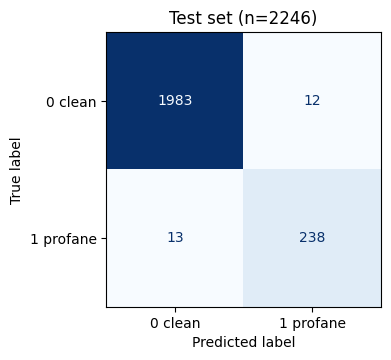

In [6]:
import evaluate
metrics, test, fig = evaluate.main()   # run once, after all settings were fixed on validation
plt.show()

In [7]:
fp = test[(test.label == 0) & (test.pred == 1)].sort_values("probability", ascending=False)
fn = test[(test.label == 1) & (test.pred == 0)].sort_values("probability")
print("false positives:", len(fp), " false negatives:", len(fn))
fp[["text", "label", "pred", "probability"]]

false positives: 12  false negatives: 13


,text,label,pred,probability
3,Шеңды сі#ейын деген зат бұл! За#бал рекламасы!,0,1,0.9985
241,Тартылмаиды нахууууу,0,1,0.9949
1417,Амыгып отырганда ойнауга болады екен.айбат айбат,0,1,0.9816
1362,Я тебе люблю собака и кошка и заеца 🐈🐱🐕🐶🐇🐰😍😚💖💝💘💌💋❣️💟💕💞💓💗❤️Супер игра я казак қазақшасы...,0,1,0.7675
1493,мал қота пас жаман неме,0,1,0.7116
1281,Ақ,0,1,0.6062
1396,Сенба тобелесетн шакыр шешен айырам мен оны эй крбулттак кара шымкент кшедеге жараба к...,0,1,0.5545
815,Отінем вайфай сыз болсао Ғо туй блин неге нау ойның ф Вайфайсыз,0,1,0.5509
1314,Білә бан бере береды зай бал,0,1,0.5408
421,Ешак тартылмай жатыр тотоқ бла,0,1,0.5320


In [8]:
fn[["text", "label", "pred", "probability"]]

,text,label,pred,probability
989,Еееееееееееең бытшыт приложение ееееееееееееең тупой бұданда жаман жазамба деп отырған...,1,0,0.0016
1634,"Щшс мұндай приложениесін,біткен шаруасы,2 жыл бұрын осындай еді өзгеріс жоқ,сол екі әр...",1,0,0.0068
1855,Бомабти нафик скачать килдим озимхам билмиман хаёлимга сике,1,0,0.0103
1245,Kotak жеген ойын болдыгой ескысы жаксы еды 10.000к беретын и жартылай казакша жартысы ...,1,0,0.0356
2114,Чё за ..... . Придворительный заказдар жок түспейді. Дальняк қосулы приложения да но т...,1,0,0.0491
1927,"Шешесгин,керемет!",1,0,0.0554
2063,кызды ким сигип корди,1,0,0.1263
1018,Беттеріңе айтайын былшиып кресло да отқаннан басқа қолдарыңнан боқ та келмейді ғой сен...,1,0,0.2876
2108,зб обновит ете бермеңдерші ең бастапқы қалпына қойсаңдаршы,1,0,0.3232
649,Жек қарн жұлам нах,1,0,0.3396


In [9]:
# a few correct predictions, including hard clean ones (negative but not profane)
ok = test[test.label == test.pred]
hard_clean = ok[(ok.label == 0) & ok.text.str.contains(r"(?i)\bмал\b|ешак|тупой|жаман|ақымақ")].head(5)
pd.concat([ok[ok.label == 1].head(5), hard_clean])[["text", "label", "pred", "probability"]]

,text,label,pred,probability
0,Қотақбас жұмыс жасалмайды,1,1,1.0000
17,Қотақсикйй ойын тартпандар!!!!,1,1,0.9999
38,котакко,1,1,0.9999
47,Пиздец ойынғо э,1,1,0.9999
55,Зайбал екен техники роботасы болмаса болат баскасы,1,1,0.9968
15,:-):-);-);-):-(:-(:'(:'(:O:O:-D:-D:-(топас катын мал карбаш,0,0,0.0962
50,Мал ишак өтірік жазбандар шықпай қоияады малмалмал,0,0,0.0073
57,Бул ойын тупойыски малски не интересный ойын буны шыгарган адам ешак😏😈🖕,0,0,0.0355
76,Ужасно жаман аудармайд даже салем депте аудармайд,0,0,0.0327
103,После обновления оте жаман болып кетти.Бурынгысы жаксы еди.Сагат сайын жана жаналыктар...,0,0,0.0101


### My solution: results and errors

The test set has 2,246 comments, 251 of them profane. It was used once, with the threshold 0.51 chosen on validation.

Profanity class: precision 0.952, recall 0.948, F1 0.950. Confusion matrix: 1,983 true negatives, 12 false positives, 13 false negatives, 238 true positives. The saved metrics and all test predictions are in results/.

A false positive means a clean review is marked as profane. The shop hides an honest review, often a negative one with words like "мал" or "тупой", and the customer feels censored. A false negative means profanity gets through and everyone sees it on the product page. For a shop, false negatives usually hurt more, but too many false positives hide real complaints and lower trust. A practical setup: hide automatically only when the probability is high (for example above 0.9), and send the middle zone (0.2 to 0.9) to a human moderator. If the moderator team prefers fewer misses, the threshold can be lowered.

Mistakes and hard examples:

1. Some false positives are my labeling mistakes, and the model is right. Examples: "Шеңды сі#ейын ... За#бал рекламасы" (my rules join letters around * and . but not #), "Тартылмаиды нахууууу" (after the repeated letters are shortened, the rule no longer matches), "зай бал" (a space inside the word), "мал қота пас" (қотақбас with a missing letter). So the model learned the letter patterns, not just my exact rules. The real F1 is probably a bit higher than reported.

2. Long comments. In "...тех подержкаларыңның 667. Бәрін исправить етіңдер..." and "...қандай далбаизм екенін түсінер..." the bad word is in the middle of a long text. I keep only the first and last 150 characters, so the model never sees it. Fix: cut long texts into 300-character windows and take the highest probability.

3. Latin script. "Kotak жеген ойын" and "Sgin unamait kotak oiyngo bul dalbaeop suka" are missed (p < 0.5). Training has very few profane examples written in Latin. My rules map Latin letters to Cyrillic, but the model input does not. Fix: use the same Latin-to-Cyrillic mapping in model_normalize, and add copies of training texts with random Latin letters, *, # and spaces.

4. Rare or very short forms: "Щшс" (the usual form is "шшс"), "зб", "нах", "сигип", and the Uzbek "сике". The model has seen few of these, and short forms like "зб" also appear in normal text.

5. Real false positives: "Шешеннің каиф" and "шешен айырам" are close to "шешеңді ..." but are not profane under my rules. "Ақ" is a two-letter text, which gives the model almost nothing to work with.

Extra check on another source: on the 63 phrases from the Kazakh Swear Words dataset, accuracy is 0.889 (cell below, in section 4). Its misses are words that are rare in reviews (салдақы, қаншық), Latin letters inside Cyrillic words ("поxyй"), and "Оттама", which my rules count as a mild insult (0) while that dataset counts it as 1.

Limitations:

- One person (me) made the labels: rules plus manual review of the unclear cases. The model partly learns to copy these rules, and the test labels come from the same rules. So the score shows agreement with my rules, not with many annotators.
- Not every text was checked by hand. A random check of negatives found about 2-3% missed profanity. I fixed those patterns, but some noise is left.
- Almost all profanity comes from app and game reviews. Marketplace reviews of goods have no profane examples, so results on goods reviews are less tested.
- Links, phones, e-mails and surnames are masked, but first names can stay in the text.

# Repository, Submission & Defense

## 4. Make your work reproducible

Your GitHub repository must include:

1. **README.md:** task definition, dataset source and labeling rules, split sizes, model choice, setup instructions, training command/notebook, prediction instructions, results, and limitations.
2. **Runnable code:** data preparation, training, evaluation, and inference. Provide either clear local setup instructions or a notebook that runs in a fresh Google Colab runtime.
3. **Dependencies and configuration:** specified package versions, training settings, and the random seed.
4. **Data and model access:** the dataset or clear instructions to obtain and prepare it; split information; and a working link to the trained model and required preprocessing files. Large files may be stored outside GitHub.
5. **Results and examples:** saved test metrics, a confusion matrix, and sample predictions with a short analysis. This explanation may be in the README or notebook; a separate report is not required.

Someone following your instructions should be able to load your saved model and predict on a new Kazakh comment without retraining. Include a simple function, command, or notebook cell for entering custom text. The training process must also be reproducible from your instructions.

### My solution: inference

The README explains setup. To predict without retraining, load the saved model with ProfanityDetector (src/predict.py), or run python src/predict.py "your comment" in a terminal. Change the list below to try your own text.

In [10]:
from predict import ProfanityDetector
det = ProfanityDetector()   # loads models/char_cnn.pt, vocab.json, config.json

my_comments = [
    "Өте жақсы тауар, тез жеткізді, рахмет!",
    "Сапасы нашар, ақшама өкіндім. Мал магазин.",
    "қотақбас ойын, ашылмайды",
    "к0тaқ ойын",                          # zero and Latin 'a' instead of о and а
    "Ойын пиздец керемет екен",
    "Реклама көп, жабылып қала береді",
    "шешеңді с*гейін мына приложениенің",
    "Жақсы подгузник, бірақ балама аллергия берді",
]
for r in det.predict(my_comments):
    print(f"{r['label']}  p={r['probability']:.3f}  {r['text']}")

0  p=0.000  Өте жақсы тауар, тез жеткізді, рахмет!
0  p=0.000  Сапасы нашар, ақшама өкіндім. Мал магазин.
1  p=1.000  қотақбас ойын, ашылмайды
1  p=0.894  к0тaқ ойын
1  p=0.999  Ойын пиздец керемет екен
0  p=0.000  Реклама көп, жабылып қала береді
1  p=0.995  шешеңді с*гейін мына приложениенің
0  p=0.000  Жақсы подгузник, бірақ балама аллергия берді


In [11]:
# extra check on a different source: phrases from the Kazakh Swear Words dataset (not used in training)
sw = pd.read_json("https://huggingface.co/datasets/Rustem-Kaimolla/kazakh-swear-words/resolve/main/sentences.jsonl", lines=True)
sw["pred"] = [r["label"] for r in det.predict(sw.text.tolist())]
print("accuracy on", len(sw), "phrases:", round((sw.pred == sw.label).mean(), 3))
sw[sw.pred != sw.label][["text", "label", "pred"]]

accuracy on 63 phrases: 0.889


,text,label,pred
25,Салдақы,1,0
26,Салдакы,1,0
28,Каншык,1,0
30,Котын кышып тур ма,1,0
33,Маған поxyй,1,0
34,Маган поxyй,1,0
36,Оттама,1,0


## AI-assistance note


Your note: I used Claude Code (Opus 5.5) for resource search, debugging, paraphrasing answer in more academic way and styling, extending them and checking the notebook for issues.

## Submission

Send your **GitHub repository link directly to the instructor on Teams by 21 November 2026**. Include your full name and student ID. Ensure the instructor and teaching assistants can access the repository, dataset instructions, and model files. Keep access tokens and credentials out of the repository.

## Grading: 3 bonus points

| Criterion | Points | What is assessed |
|---|---|---|
| Data and training | 1.0 | Suitable labeled data, clear splits, justified preprocessing/model choice, and a model you trained or fine-tuned. |
| Repository and evaluation | 1.0 | Runnable code, accessible model, clear instructions, valid test metrics, and analysis of errors. |
| Individual defense | 1.0 | Understanding of the complete solution and ability to explain and modify your own code. |

Partial credit is available within each criterion. No fixed accuracy or F1 threshold applies. Marks reflect correct implementation, reproducibility, and understanding.

## Be ready for the individual defense

You should be able to trace one comment from raw text to prediction; explain labels and data splits; describe your model, training objective, and settings; interpret precision, recall, F1, and the confusion matrix; explain mistakes; and make a small change to the code or run it on new examples.